# Step 7: Model Explainability Using SHAP (Shapley Additive exPlanations)
## Cell2Cell Telecom Customer Churn Prediction

### Academic Rubric & Viva Alignment
- **Evaluation Component:** Innovation & Model Explainability (10 Marks)
- **Theoretical Foundation:** Cooperative Game Theory (Shapley Values: Efficiency, Symmetry, Dummy, Additivity)
- **Algorithm:** `shap.TreeExplainer` (Lundberg et al., *Nature Machine Intelligence* 2020) with exact polynomial-time evaluation $O(TLD^2)$
- **Model Evaluated:** Champion Tuned XGBoost (`models/best_xgboost.joblib`)
- **Evaluation Set:** Untouched Test Partition ($N = 14,210$, 63 features)

---

### 1. Environment Setup & Data Loading
We load the trained champion XGBoost classifier, the untouched test set (`X_test_final.csv`, `y_test_final.csv`), and the fitted preprocessor to enable translation back to physical business units.

In [1]:
import os
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150

# Load model and data
model = joblib.load('../models/best_xgboost.joblib')
X_test = pd.read_csv('../data/processed/X_test_final.csv')
y_test = pd.read_csv('../data/processed/y_test_final.csv').values.ravel()
preprocessor = joblib.load('../models/final_preprocessor.joblib')

num_cols = list(preprocessor.named_transformers_['num'].feature_names_in_)
scaler = preprocessor.named_transformers_['num'].named_steps['scaler']
means = dict(zip(num_cols, scaler.mean_))
scales = dict(zip(num_cols, scaler.scale_))

print(f"XGBoost model loaded: {type(model).__name__}")
print(f"Test features shape: {X_test.shape}")
print(f"Test target distribution: Churned = {np.sum(y_test == 1)} ({np.mean(y_test)*100:.2f}%), Retained = {np.sum(y_test == 0)}")

C:\Users\gumbh\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


XGBoost model loaded: XGBClassifier
Test features shape: (14210, 63)
Test target distribution: Churned = 4122 (29.01%), Retained = 10088


### 2. Computing Exact Shapley Values via TreeExplainer
`shap.TreeExplainer` computes the exact local attribution of each feature to the model's raw margin output (log-odds):
$$\sum_{j=1}^{M} \phi_j(x) = f(x) - E[f(X)]$$
where $E[f(X)]$ is the expected base value and $\phi_j(x)$ is the SHAP value for feature $j$.

In [2]:
explainer = shap.TreeExplainer(model)
shap_explanation = explainer(X_test)
shap_values = shap_explanation.values
base_val = float(explainer.expected_value[0] if isinstance(explainer.expected_value, np.ndarray) else explainer.expected_value)

print(f"SHAP values matrix: {shap_values.shape}")
print(f"Base value (expected margin in log-odds): {base_val:.5f}")
print(f"Implied base churn probability: {1 / (1 + np.exp(-base_val)):.4f}")

SHAP values matrix: (14210, 63)
Base value (expected margin in log-odds): 0.00003
Implied base churn probability: 0.5000


### 3. Global Feature Importance
We calculate the mean absolute SHAP value across all 14,210 test customers to rank features by overall predictive power.

Top 15 Features by Global SHAP Importance:
              feature  mean_abs_shap  mean_shap  rank
              eqpdays       0.228372  -0.010602     1
               months       0.155312  -0.021470     2
              changem       0.144942  -0.025287     3
             uniqsubs       0.087382  -0.012280     4
         cost_per_mou       0.085065  -0.012738     5
                 age1       0.077610  -0.002724     6
network_friction_rate       0.069424  -0.005990     7
             recchrge       0.065552  -0.008416     8
    handset_age_ratio       0.060212  -0.006747     9
       overage_burden       0.056014  -0.006734    10
              incalls       0.055505   0.004132    11
             creditaa       0.053550  -0.003407    12
                  mou       0.048040   0.008860    13
              retcall       0.044975  -0.006898    14
               refurb       0.039528  -0.004008    15


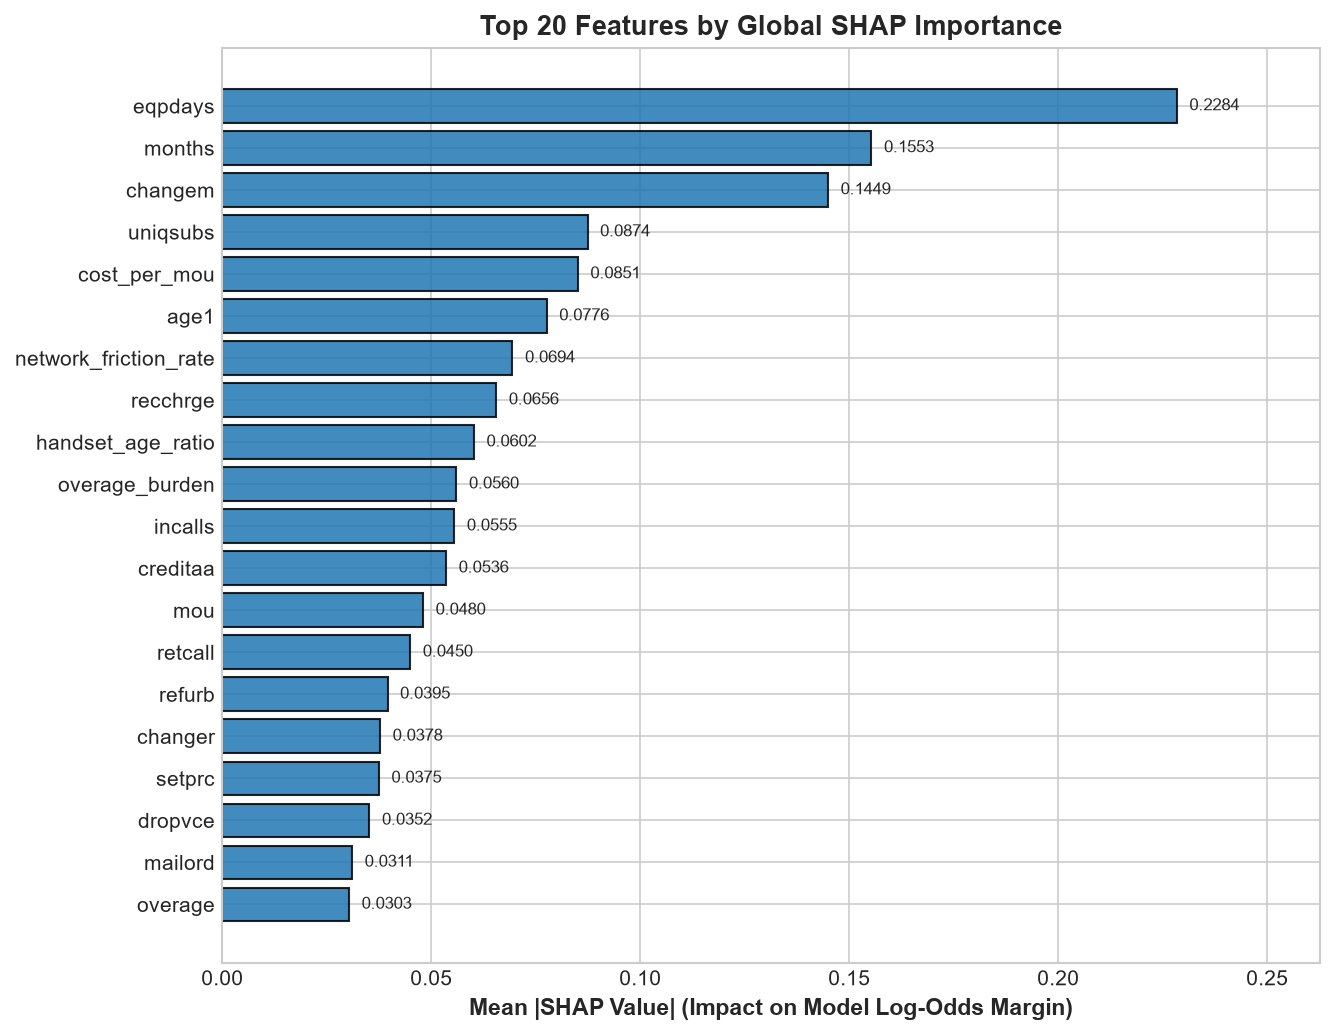

In [3]:
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
shap_ranking = pd.DataFrame({
    'feature': X_test.columns,
    'mean_abs_shap': mean_abs_shap,
    'mean_shap': np.mean(shap_values, axis=0)
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
shap_ranking['rank'] = shap_ranking.index + 1

print("Top 15 Features by Global SHAP Importance:")
print(shap_ranking.head(15).to_string(index=False))

# Bar plot
top20 = shap_ranking.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(top20['feature'], top20['mean_abs_shap'], color='#1f77b4', edgecolor='black', alpha=0.85)
ax.set_xlabel('Mean |SHAP Value| (Impact on Model Log-Odds Margin)', fontsize=11, fontweight='bold')
ax.set_title('Top 20 Features by Global SHAP Importance', fontsize=13, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.003, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=8)
ax.set_xlim(0, max(top20['mean_abs_shap']) * 1.15)
plt.tight_layout()
plt.show()

### 4. Summary Beeswarm Plot
The beeswarm plot displays both feature importance and the direction of impact. Each dot is an individual customer, colored by whether their feature value was high (red) or low (blue).

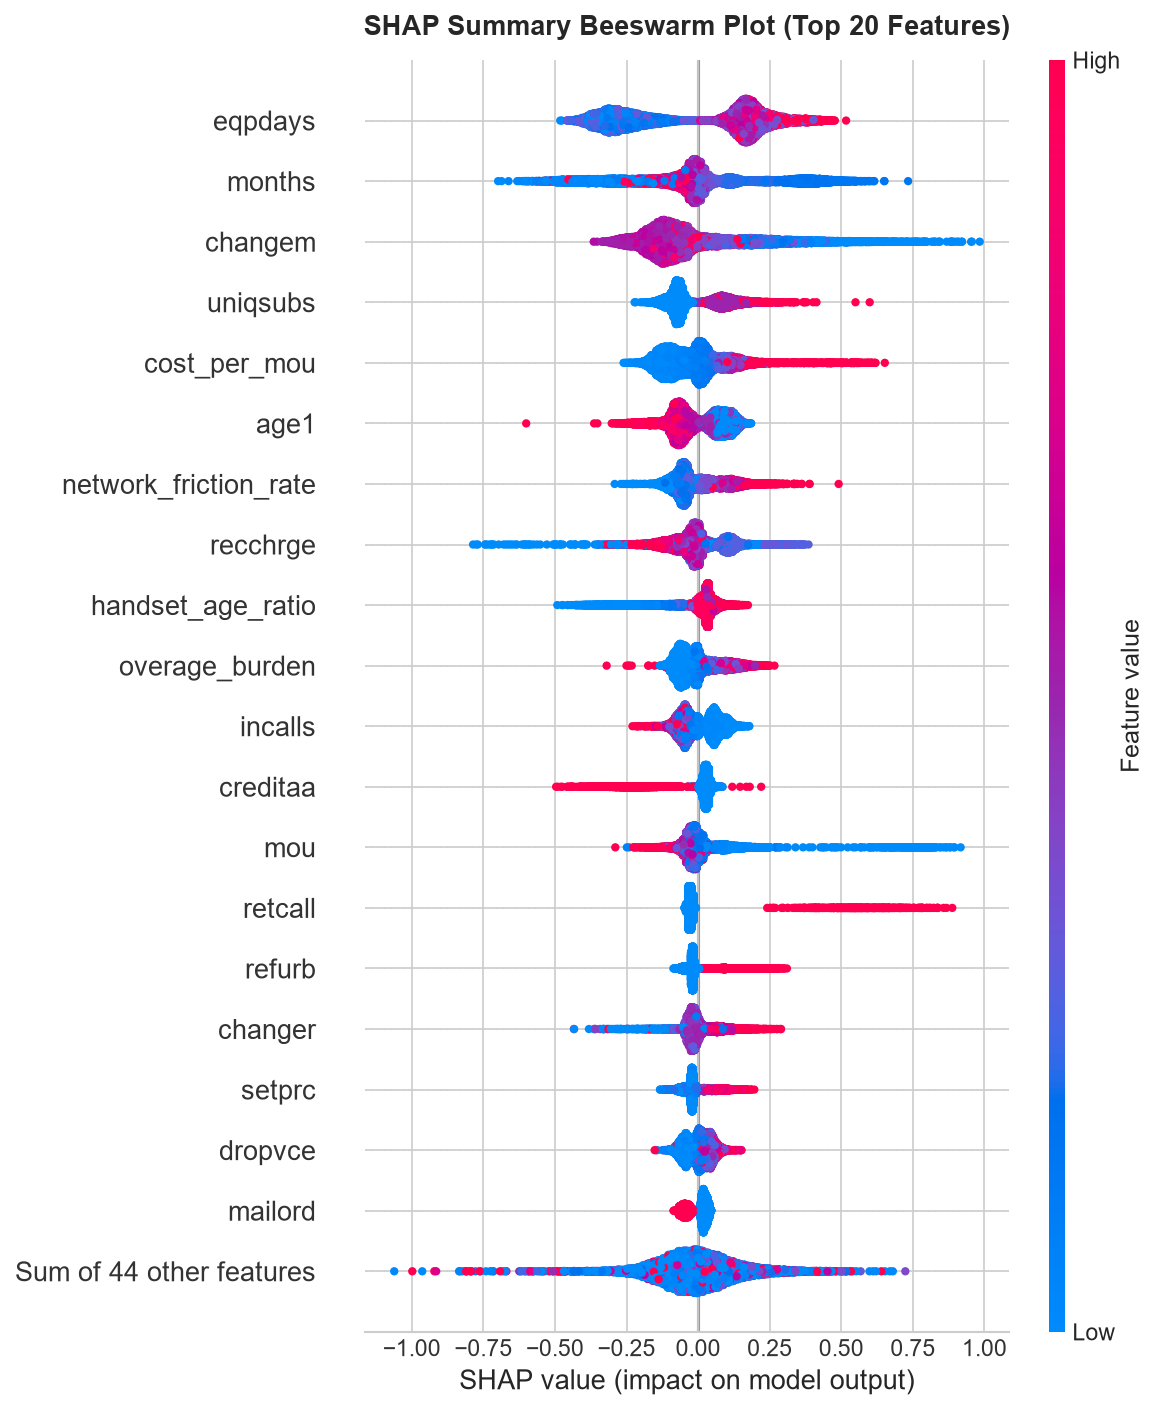

In [4]:
fig = plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_explanation, max_display=20, show=False)
plt.title('SHAP Summary Beeswarm Plot (Top 20 Features)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### 5. Dependence Plots: Revealing Non-Linear Inflection Points
Dependence plots show how the SHAP contribution varies with the feature value, revealing non-linear thresholds and interaction patterns.

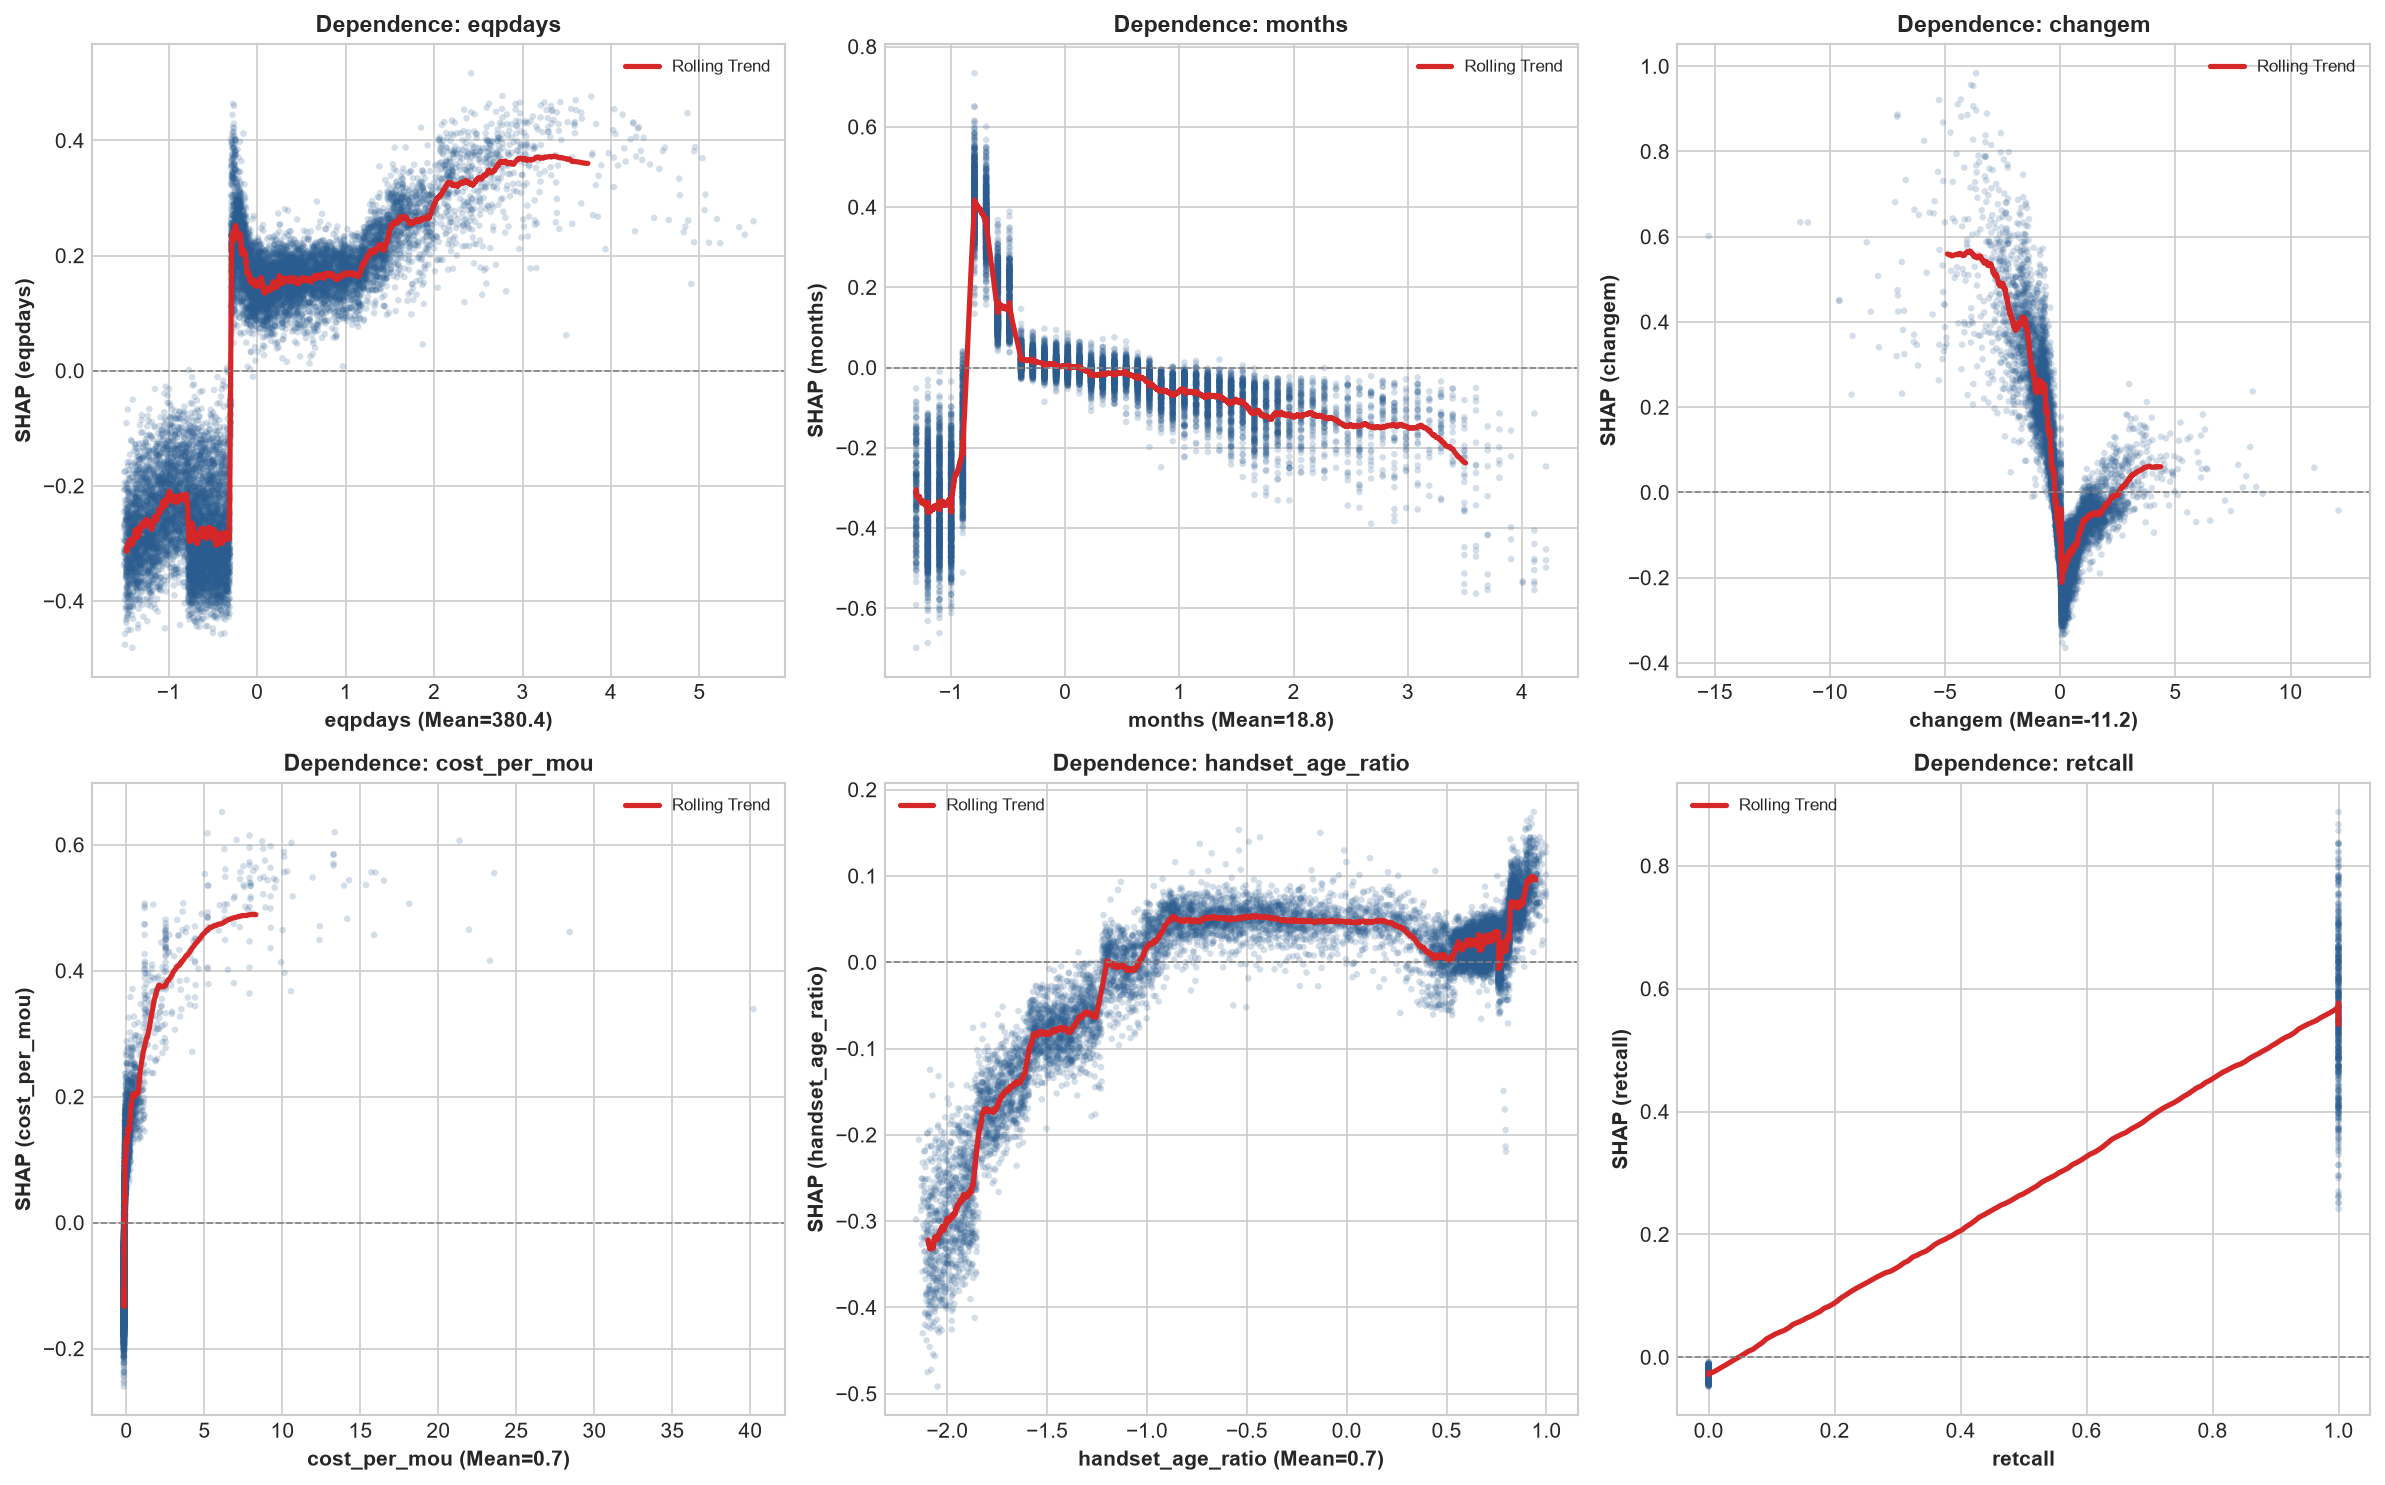

In [5]:
dep_features = ['eqpdays', 'months', 'changem', 'cost_per_mou', 'handset_age_ratio', 'retcall']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, feat in enumerate(dep_features):
    ax = axes[idx]
    f_idx = list(X_test.columns).index(feat)
    x_val = X_test[feat].values
    y_val = shap_values[:, f_idx]
    
    ax.scatter(x_val, y_val, c='#2b5c8f', alpha=0.2, s=10, edgecolors='none')
    
    # Trend
    sort_idx = np.argsort(x_val)
    xs, ys = x_val[sort_idx], y_val[sort_idx]
    w = max(50, len(xs) // 100)
    rx = pd.Series(xs).rolling(w, center=True).mean().dropna()
    ry = pd.Series(ys).rolling(w, center=True).mean().dropna()
    ax.plot(rx, ry, color='#d62728', linewidth=2.5, label='Rolling Trend')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    
    xlabel = f"{feat} (Mean={means[feat]:.1f})" if feat in means else feat
    ax.set_xlabel(xlabel, fontsize=10, fontweight='bold')
    ax.set_ylabel(f'SHAP ({feat})', fontsize=10, fontweight='bold')
    ax.set_title(f'Dependence: {feat}', fontsize=11, fontweight='bold')
    ax.legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

### 6. Local Explanations: 3 Representative Customer Personas
We analyze 3 real customers from the untouched test set:
1. **High Churn Risk Customer (#606)**: Churn probability = 88.08% (Actual Churn = 1)
2. **Medium (Borderline) Risk Customer (#13293)**: Churn probability = 46.31% (Actual Churn = 0, at optimal threshold $\tau^* = 0.4631$)
3. **Low Churn Risk Customer (#452)**: Churn probability = 7.88% (Actual Churn = 0, Loyal)

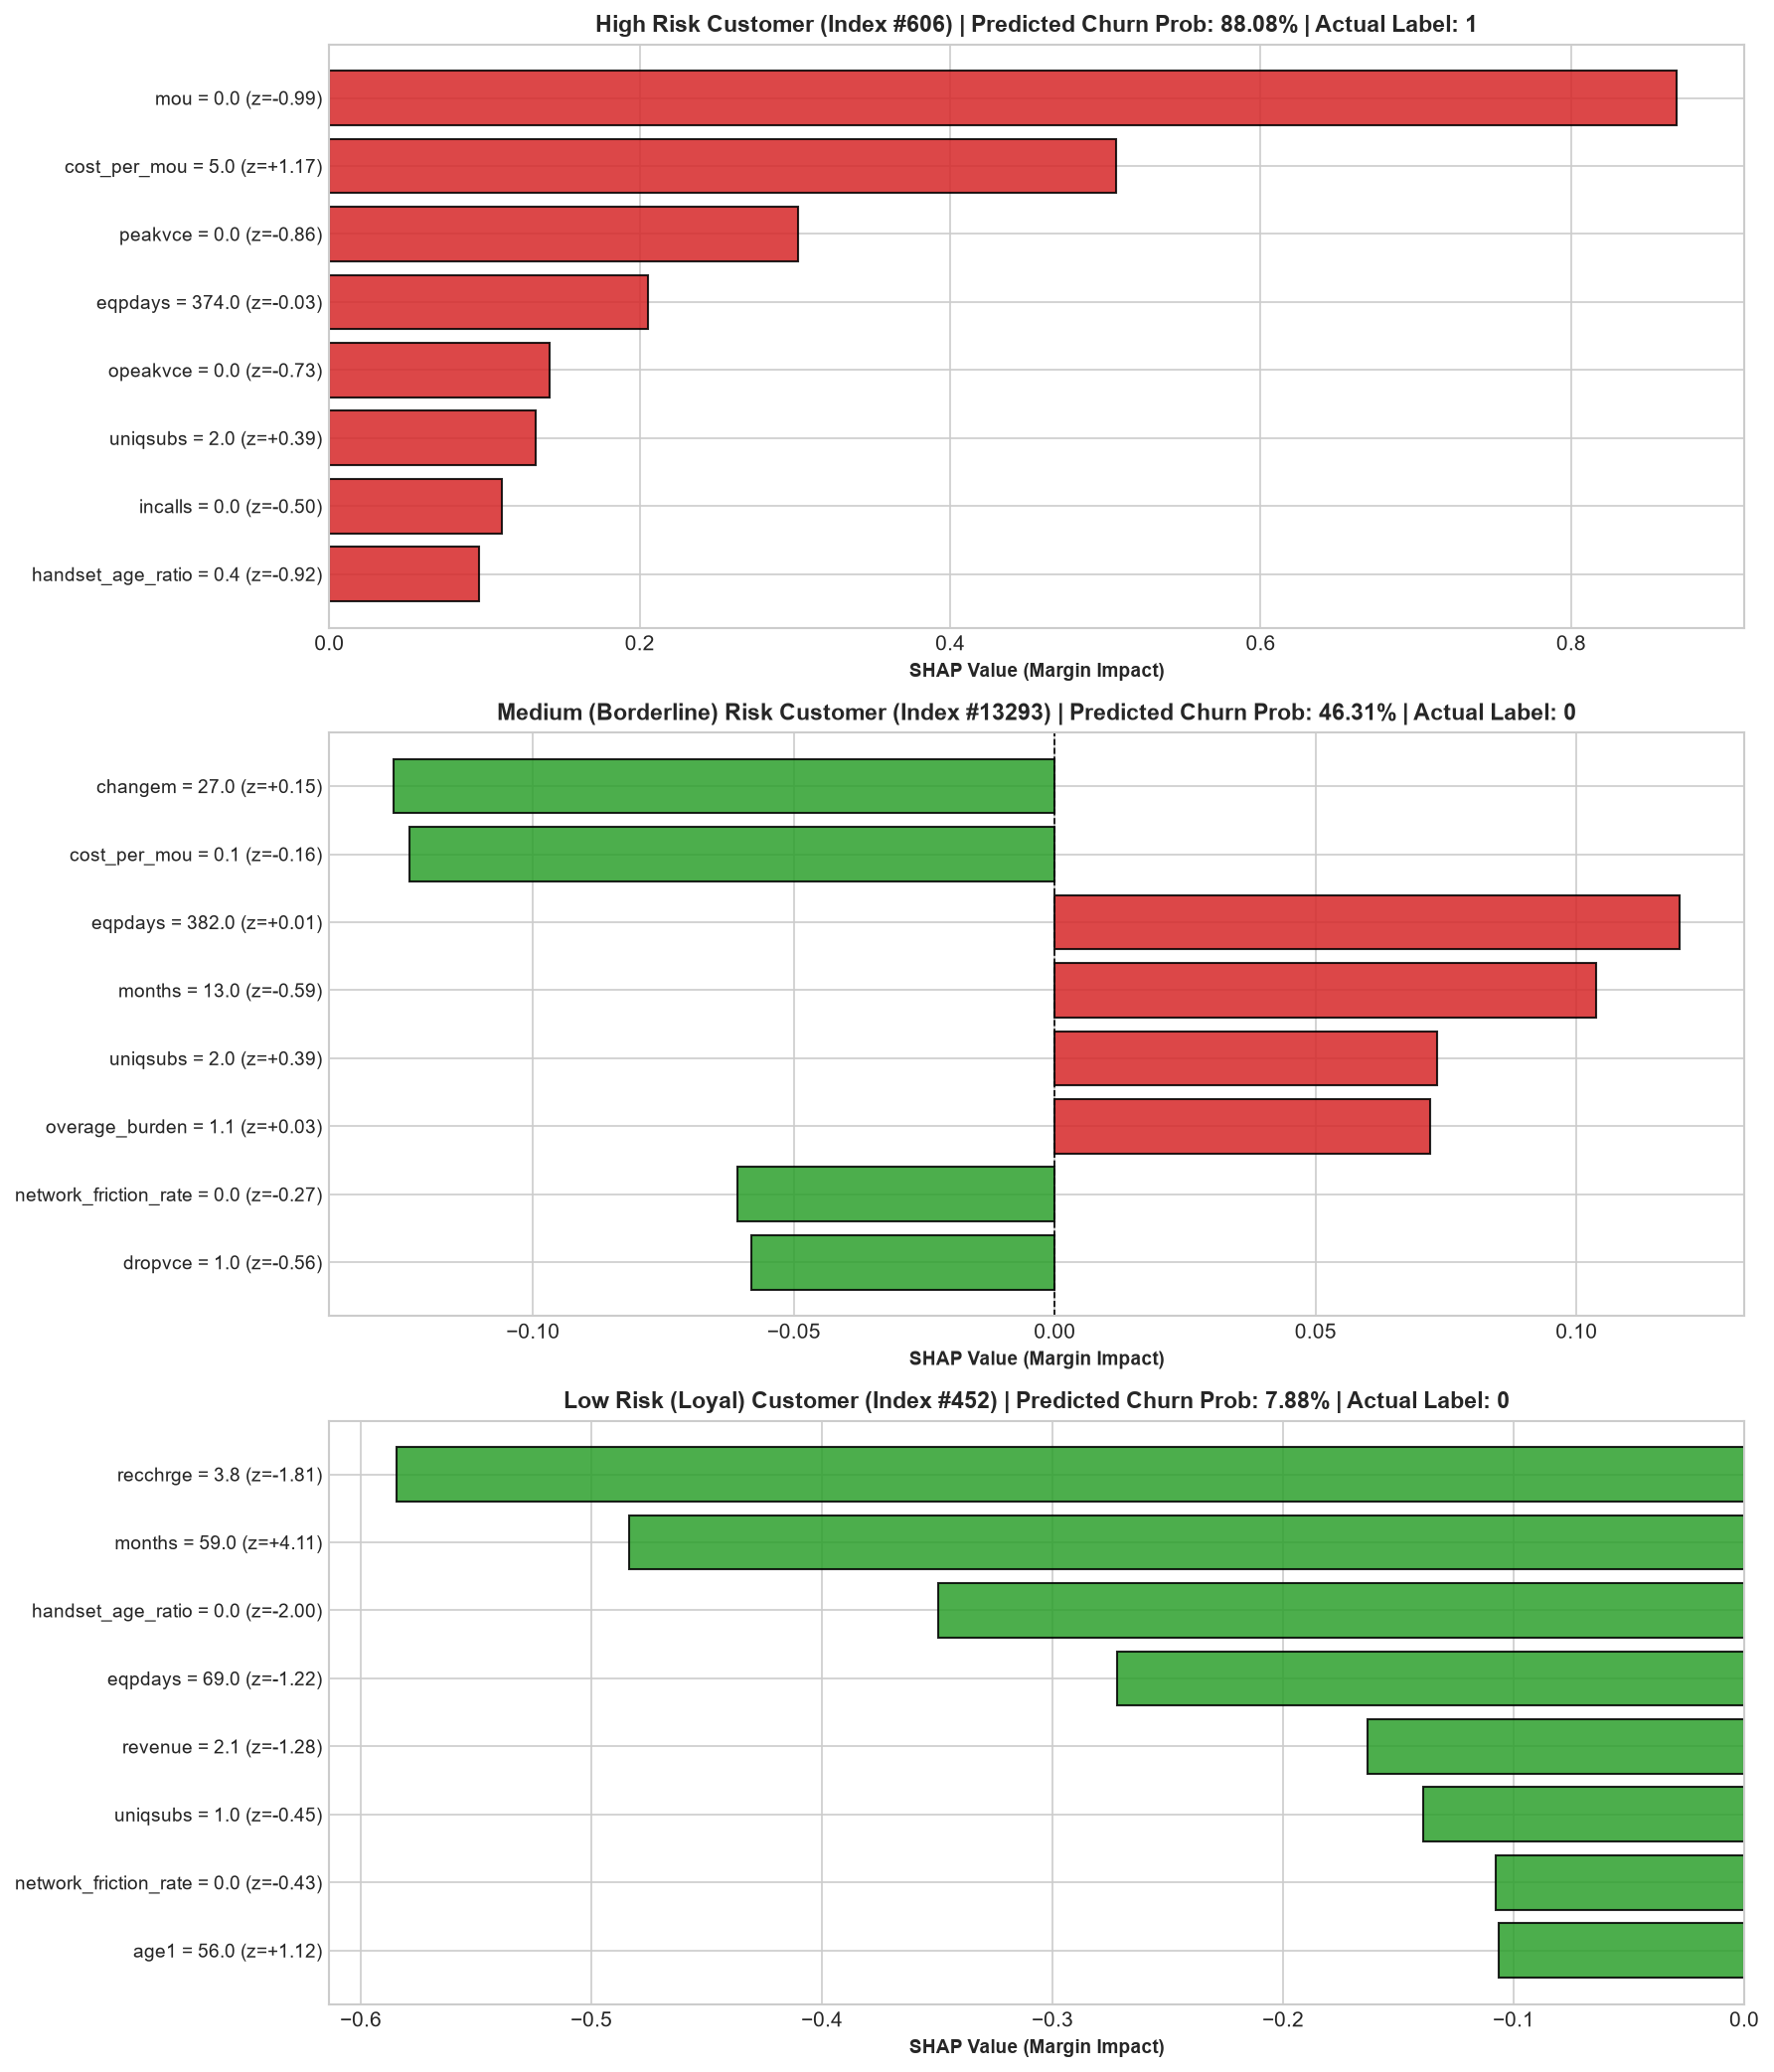

In [6]:
probs = model.predict_proba(X_test)[:, 1]
personas = [
    ('High Risk Customer', 606),
    ('Medium (Borderline) Risk Customer', 13293),
    ('Low Risk (Loyal) Customer', 452)
]

fig, axes = plt.subplots(3, 1, figsize=(12, 14))
for ax_idx, (name, c_idx) in enumerate(personas):
    c_prob = probs[c_idx]
    c_true = int(y_test[c_idx])
    c_shap = shap_values[c_idx]
    
    top_idx = np.argsort(np.abs(c_shap))[::-1][:8]
    feat_names = [X_test.columns[i] for i in top_idx][::-1]
    feat_shap = [c_shap[i] for i in top_idx][::-1]
    
    colors = ['#d62728' if v > 0 else '#2ca02c' for v in feat_shap]
    labels = []
    for f in feat_names:
        val = X_test.iloc[c_idx][f]
        if f in means:
            raw = val * scales[f] + means[f]
            labels.append(f"{f} = {raw:.1f} (z={val:+.2f})")
        else:
            labels.append(f"{f} = {int(val)}")
            
    ax = axes[ax_idx]
    ax.barh(range(len(feat_names)), feat_shap, color=colors, edgecolor='black', alpha=0.85)
    ax.set_yticks(range(len(feat_names)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_title(f"{name} (Index #{c_idx}) | Predicted Churn Prob: {c_prob:.2%} | Actual Label: {c_true}",
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('SHAP Value (Margin Impact)', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Strategic Business Translation & Actionable Interventions

| Feature | Observed Direction | SHAP Impact | Telecom Business Interpretation | Actionable Retention Intervention |
|:---|:---|:---|:---|:---|
| `eqpdays` | High $\to$ +Churn | Rank #1 (0.2284) | Aging handset without upgrade signals technological obsolescence and end-of-contract vulnerability. | Proactive subsidized hardware upgrade offer at Day 330 (before 12-month mark). |
| `months` | Low $\to$ +Churn | Rank #2 (0.1553) | New customers (<14 months) have higher churn propensity before building relationship stickiness. | Onboarding engagement programs, 90-day check-ins, and early tenure loyalty rewards. |
| `changem` | Negative $\to$ +Churn | Rank #3 (0.1449) | Sudden contraction in minutes of use indicates disengagement or migration to competing SIM/Wi-Fi. | Automated trigger when `changem < -20%`: send bonus minutes or customer satisfaction outreach. |
| `cost_per_mou` | High $\to$ +Churn | Rank #5 (0.0851) | High unit price per minute causes perceived billing injustice and plan mismatch. | Plan right-sizing: automatically recommend an optimized plan with lower rate/minute. |
| `network_friction_rate` | High $\to$ +Churn | Rank #7 (0.0694) | Blocked and dropped calls frustrate subscribers, severely degrading quality of experience (QoE). | VIP cell tower capacity boost and proactive service apology credits for friction > 3%. |
| `retcall` | Active $\to$ +Churn | Rank #14 (0.0450) | Inbound call to customer retention department is an explicit signal of imminent attrition. | Empower retention agents with instant credits, plan discounts, or immediate device renewal. |

> **Methodological Caveat (Correlation vs Causation):**
> SHAP quantifies statistical attribution within the trained XGBoost model, not causal intervention effects. For example, older handset age (`eqpdays`) correlates with churn because customers whose contracts expired keep their phones while shopping for competitors. Simply forcing a customer to keep a phone longer without an upgrade does not prevent churn.